# TensorForge model recalibration — 75/25 holdout

This notebook reproduces a deterministic, stratified 75/25 train/test evaluation using **only** `datasets/train.csv` for the split. The 25% fold is scored before the final refit. The supplied `datasets/validation.csv` is not used to calculate these scores; after the evaluation, the deployable model is retrained on all 4,800 labeled examples. The optional `language` feature is included when present in a ticket and may be omitted at inference.

The data is synthetic workshop data. Held-out results measure this dataset and do not guarantee performance on live customer tickets.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from scripts.train_model import run_training

metrics, holdout = run_training(
    train_path=ROOT / "datasets/train.csv",
    validation_path=ROOT / "datasets/validation.csv",
    config_path=ROOT / "configs/training.json",
    output_dir=ROOT / "artifacts",
    test_size=0.25,
    random_state=42,
)
print(metrics["evaluation_note"])
print("Split:", metrics["evaluation_split"])


Training holdout models on 3000 examples


Fresh fit: category on 3000 labeled tickets


Fresh fit: secondary_category on 3000 labeled tickets


Fresh fit: is_urgent on 3000 labeled tickets


Refitting deployment models on 4800 labeled examples


...

Fresh fit: secondary_category on 4800 labeled tickets


Fresh fit: is_urgent on 4800 labeled tickets


{
  "category": {
    "accuracy": 0.99,
    "macro_f1": 0.9892
  },
  "secondary_category": {
    "accuracy": 0.998,
    "macro_f1": 0.9884
  },
  "is_urgent": {
    "accuracy": 0.999,
    "macro_f1": 0.9971
  }
}


Saved fresh artifact to /Users/geemalfernando/Documents/projects/Tensorforge/artifacts/model.joblib


Metrics are from the untouched 25% stratified test fold of train.csv. After scoring, the deployment artifact was refit on train.csv plus validation.csv; do not evaluate that final artifact on these same examples.
Split: {'method': 'stratified random split by primary category from train.csv only', 'test_size': 0.25, 'random_state': 42, 'fit_examples': 3000, 'test_examples': 1000, 'validation_file_used_for_test_scoring': False}


## Held-out scores

Accuracy and macro-F1 are calculated from the predictions of models fitted on the 75% training fold. Macro-F1 weights each class equally, which helps reveal weak performance on less frequent labels.

In [2]:
score_table = pd.DataFrame(metrics["validation"]).T
score_table.index.name = "target"
display((100 * score_table).round(2).rename(columns={"accuracy": "accuracy_percent", "macro_f1": "macro_f1_percent"}))

print("Top primary-category confusions:")
display(pd.DataFrame(metrics["top_category_confusions"]))

print("Primary category performance by language:")
display(pd.DataFrame(metrics["category_by_language"]).T)


,accuracy_percent,macro_f1_percent
target,,
category,99.0,98.92
secondary_category,99.8,98.84
is_urgent,99.9,99.71


Top primary-category confusions:


,actual,predicted,count
0,order_missing_wrong,delivery_delay,1
1,ride_trip_issue,account_promo,1
2,ride_trip_issue,lost_item,1
3,lost_item,ride_trip_issue,1
4,safety_conduct,delivery_delay,1
5,order_missing_wrong,app_technical,1
6,lost_item,delivery_delay,1
7,account_promo,app_technical,1
8,food_quality,general_inquiry,1
9,payment_refund,delivery_delay,1


Primary category performance by language:


,count,accuracy,macro_f1
en,356.0,0.9831,0.9825
mixed,23.0,1.0000,1.0000
si,198.0,1.0000,1.0000
singlish,255.0,0.9961,0.9978
ta,146.0,1.0000,1.0000
tanglish,22.0,0.8636,0.7778


## Visual diagnostics

The confusion matrix uses true categories on rows and predicted categories on columns. The class-score chart highlights any category that needs more examples or a later model iteration.

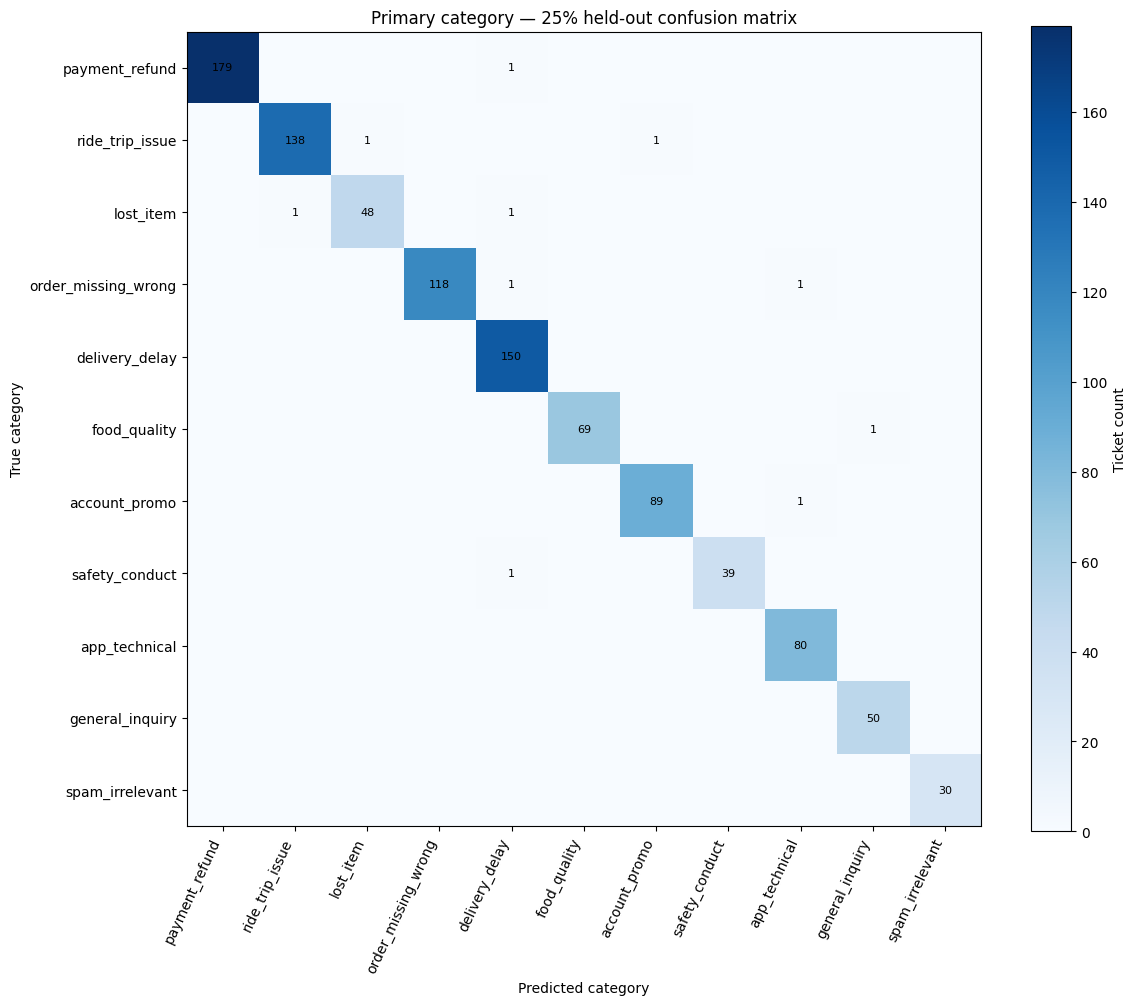

,precision,recall,f1-score,support
lost_item,97.96,96.00,96.97,50.0
delivery_delay,97.40,100.00,98.68,150.0
safety_conduct,100.00,97.50,98.73,40.0
app_technical,97.56,100.00,98.77,80.0
account_promo,98.89,98.89,98.89,90.0
ride_trip_issue,99.28,98.57,98.92,140.0
general_inquiry,98.04,100.00,99.01,50.0
order_missing_wrong,100.00,98.33,99.16,120.0
food_quality,100.00,98.57,99.28,70.0
payment_refund,100.00,99.44,99.72,180.0


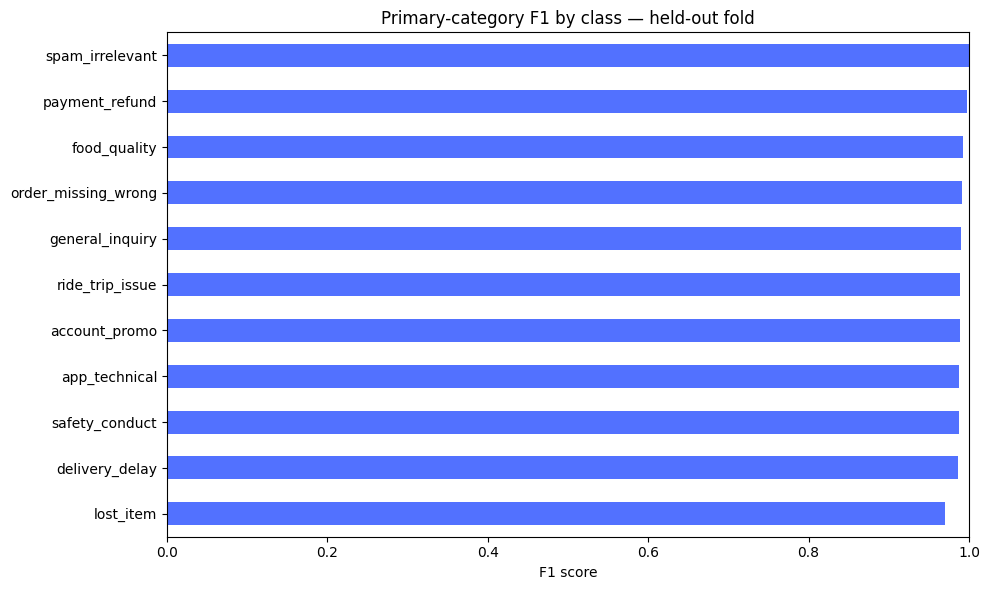

In [3]:
matrix = metrics["category_confusion_matrix"]["rows_actual_columns_predicted"]
labels = metrics["category_confusion_matrix"]["labels"]
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(matrix, cmap="Blues")
ax.set(
    title="Primary category — 25% held-out confusion matrix",
    xlabel="Predicted category",
    ylabel="True category",
    xticks=range(len(labels)),
    yticks=range(len(labels)),
)
ax.set_xticklabels(labels, rotation=65, ha="right")
ax.set_yticklabels(labels)
for row in range(len(labels)):
    for column in range(len(labels)):
        if matrix[row][column]:
            ax.text(column, row, str(matrix[row][column]), ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Ticket count")
fig.tight_layout()
plt.show()

report = metrics["category_report"]
class_scores = pd.DataFrame(
    {label: report[label] for label in labels}
).T[["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
display((100 * class_scores[["precision", "recall", "f1-score"]]).round(2).join(class_scores[["support"]]))
class_scores["f1-score"].plot.barh(figsize=(10, 6), color="#5271ff", title="Primary-category F1 by class — held-out fold")
plt.xlabel("F1 score")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


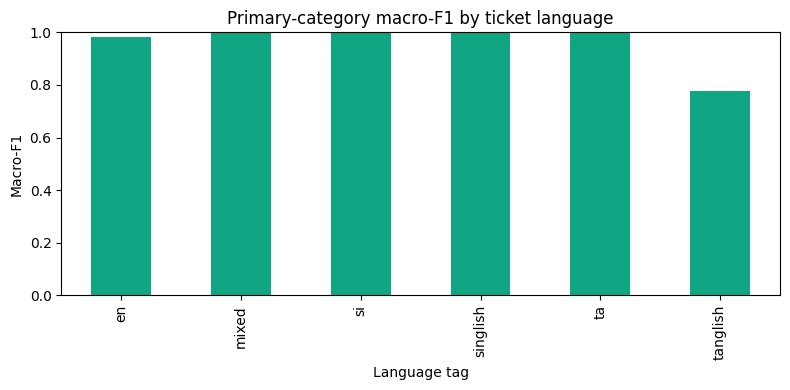

,count,accuracy,macro_f1
en,356.0,0.9831,0.9825
mixed,23.0,1.0000,1.0000
si,198.0,1.0000,1.0000
singlish,255.0,0.9961,0.9978
ta,146.0,1.0000,1.0000
tanglish,22.0,0.8636,0.7778


In [4]:
language_scores = pd.DataFrame(metrics["category_by_language"]).T.sort_index()
language_scores["macro_f1"].plot.bar(figsize=(8, 4), color="#11a683", title="Primary-category macro-F1 by ticket language")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.xlabel("Language tag")
plt.tight_layout()
plt.show()
display(language_scores)


## Delivery-delay vs. lost-property check

These are sanity examples, separate from the measured holdout score. The matrix below also isolates the two categories most relevant to the reported routing issue.

In [5]:
category_index = {label: index for index, label in enumerate(labels)}
pair = ["lost_item", "delivery_delay"]
pair_matrix = pd.DataFrame(
    [[matrix[category_index[truth]][category_index[predicted]] for predicted in pair] for truth in pair],
    index=["true: " + label for label in pair],
    columns=["predicted: " + label for label in pair],
)
display(pair_matrix)

from app.model import TicketModel

model = TicketModel.load(ROOT / "artifacts/model.joblib")
smoke_tickets = [
    {"channel": "chat", "subject": "", "text": "My food order is delayed and still has not arrived."},
    {"channel": "chat", "subject": "", "text": "I left my phone in the car after my ride."},
]
smoke_results = model.predict_many(smoke_tickets)
display(pd.DataFrame([
    {"ticket": ticket["text"], "predicted_category": result["category"], "confidence": result["confidence"]}
    for ticket, result in zip(smoke_tickets, smoke_results)
]))
assert smoke_results[0]["category"] == "delivery_delay"
assert smoke_results[1]["category"] == "lost_item"

print("Final deployment artifact:", ROOT / "artifacts/model.joblib")
print("Saved holdout metrics:", ROOT / "artifacts/evaluation_metrics.json")


,predicted: lost_item,predicted: delivery_delay
true: lost_item,48,1
true: delivery_delay,0,150


,ticket,predicted_category,confidence
0,My food order is delayed and still has not arr...,delivery_delay,0.997723
1,I left my phone in the car after my ride.,lost_item,0.999815


Final deployment artifact: /Users/geemalfernando/Documents/projects/Tensorforge/artifacts/model.joblib
Saved holdout metrics: /Users/geemalfernando/Documents/projects/Tensorforge/artifacts/evaluation_metrics.json
